# 01. Khám Phá Dữ Liệu (EDA) — Phân Loại Rủi Ro Khoản Vay

- **Đề tài**: Phân loại rủi ro khoản vay
- **Dataset**: Loan Approval | Classification (`data/raw/loan_data.csv`)
- **Mục tiêu**: Hiểu rõ cấu trúc 14 cột (13 đặc trưng + biến mục tiêu `loan_status`), kiểm tra dữ liệu thiếu/trùng lặp, đánh giá mức độ mất cân bằng lớp và phát hiện các giá trị ngoại lai (outlier) trước khi tiền xử lý.

---

## Phần 1: Tổng quan dữ liệu
- Đọc file `../data/raw/loan_data.csv`
- Kiểm tra kích thước (`shape`), 5 dòng đầu (`head`), kiểu dữ liệu (`info`), giá trị thiếu (`isnull`) và dòng trùng lặp (`duplicated`).

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/loan_data.csv")
print("Kích thước (dòng, cột):", df.shape)
display(df.head())

Kích thước (dòng, cột): (45000, 14)


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [2]:
df.info()
print("\nSố giá trị thiếu (null) theo cột:")
print(df.isnull().sum())
print("\nSố dòng bị trùng lặp:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  45000 non-n

## Phần 2: Phân tích biến mục tiêu (`loan_status`)
- Đếm số lượng và tỷ lệ phần trăm giữa lớp `0` (Từ chối) và lớp `1` (Được duyệt).
- Vẽ biểu đồ cột (`countplot`) để đánh giá mức độ mất cân bằng lớp (class imbalance).

Số lượng từng lớp:
loan_status
0    35000
1    10000
Name: count, dtype: int64

Tỷ lệ phần trăm (%):
loan_status
0    77.78
1    22.22
Name: proportion, dtype: float64


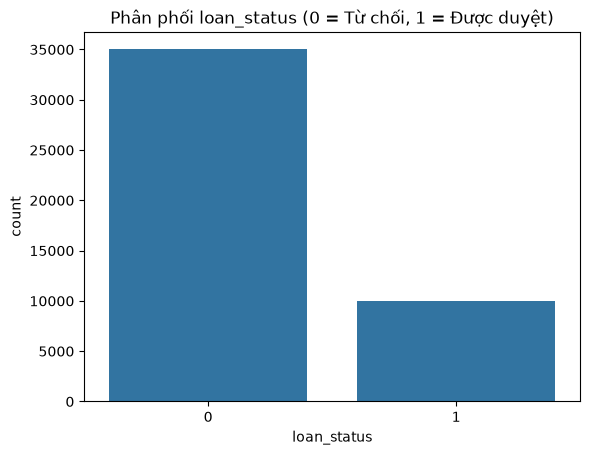

In [3]:
print("Số lượng từng lớp:")
print(df["loan_status"].value_counts())

print("\nTỷ lệ phần trăm (%):")
print(df["loan_status"].value_counts(normalize=True).mul(100).round(2))

sns.countplot(data=df, x="loan_status")
plt.title("Phân phối loan_status (0 = Từ chối, 1 = Được duyệt)")
plt.show()

## Phần 3: Thống kê mô tả & Soi Outlier các cột số
- Dùng `df.describe().T` kiểm tra `min`, `max`, trung vị (`50%`) của 8 cột số.
- Phát hiện các giá trị ngoại lai bất hợp lý (ví dụ `person_age > 100`, `person_emp_exp` lớn bất thường).

In [4]:
display(df.describe().T)

print("Số dòng có tuổi > 100:", (df["person_age"] > 100).sum())
display(df[df["person_age"] > 100][["person_age", "person_emp_exp", "person_income", "loan_status"]])

,count,mean,std,min,25%,50%,75%,max
person_age,45000.0,27.764178,6.045108,20.00,24.00,26.00,30.00,144.00
person_income,45000.0,80319.053222,80422.498632,8000.00,47204.00,67048.00,95789.25,7200766.00
person_emp_exp,45000.0,5.410333,6.063532,0.00,1.00,4.00,8.00,125.00
loan_amnt,45000.0,9583.157556,6314.886691,500.00,5000.00,8000.00,12237.25,35000.00
loan_int_rate,45000.0,11.006606,2.978808,5.42,8.59,11.01,12.99,20.00
loan_percent_income,45000.0,0.139725,0.087212,0.00,0.07,0.12,0.19,0.66
cb_person_cred_hist_length,45000.0,5.867489,3.879702,2.00,3.00,4.00,8.00,30.00
credit_score,45000.0,632.608756,50.435865,390.00,601.00,640.00,670.00,850.00
loan_status,45000.0,0.222222,0.415744,0.00,0.00,0.00,0.00,1.00


Số dòng có tuổi > 100: 7


,person_age,person_emp_exp,person_income,loan_status
81,144.0,125,300616.0,0
183,144.0,121,241424.0,0
575,123.0,101,97140.0,0
747,123.0,100,94723.0,0
32297,144.0,124,7200766.0,0
37930,116.0,93,5545545.0,0
38113,109.0,85,5556399.0,0


## Phần 4: Mối liên hệ giữa các đặc trưng và `loan_status`
- Biến phân loại: So sánh tỷ lệ duyệt vay theo `previous_loan_defaults_on_file`, `person_home_ownership`, `loan_intent`, `person_education`.
- Biến số: Vẽ `heatmap` tương quan (`corr()`) và `boxplot` (ví dụ `loan_int_rate`, `loan_percent_income`, `credit_score` theo `loan_status`).

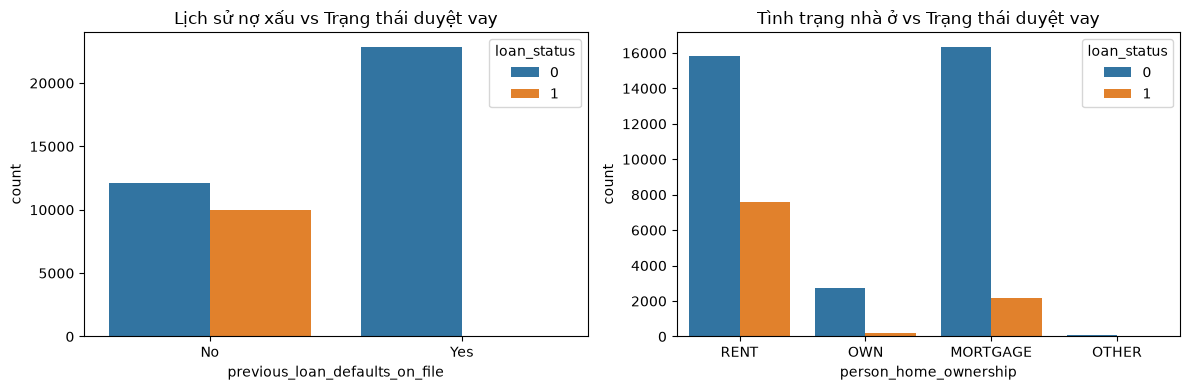

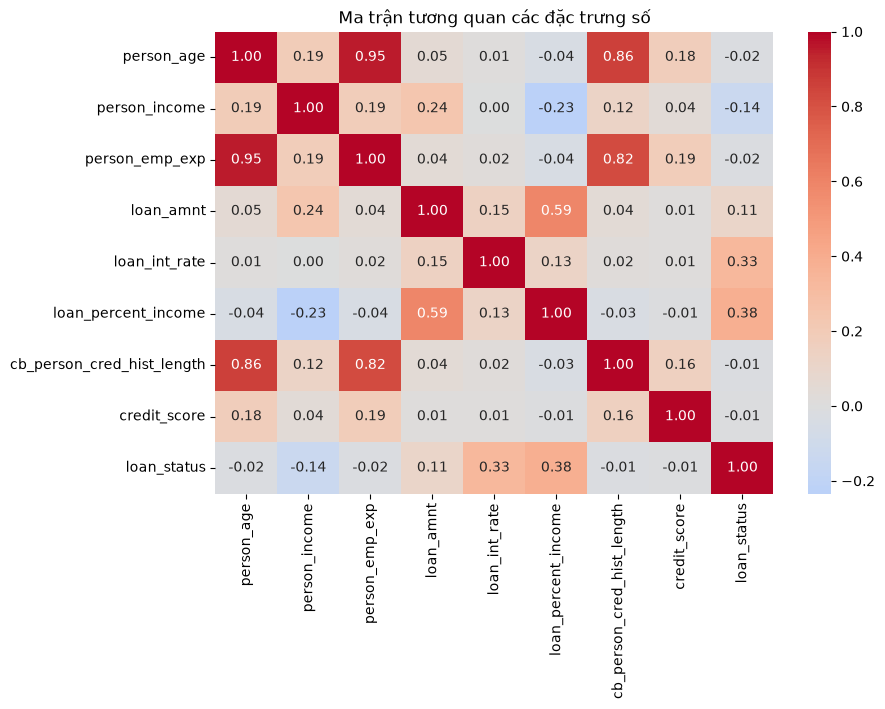

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="previous_loan_defaults_on_file", hue="loan_status", ax=axes[0])
axes[0].set_title("Lịch sử nợ xấu vs Trạng thái duyệt vay")

sns.countplot(data=df, x="person_home_ownership", hue="loan_status", ax=axes[1])
axes[1].set_title("Tình trạng nhà ở vs Trạng thái duyệt vay")
plt.tight_layout()
plt.show()

# Heatmap tương quan giữa các cột số với loan_status
plt.figure(figsize=(9, 6))
corr = df.select_dtypes(include="number").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Ma trận tương quan các đặc trưng số")
plt.show()

## Phần 5: Kiểm tra tính nhất quán & xung đột nhãn
- Kiểm tra trùng lặp trên `13` đặc trưng đầu vào (phát hiện trường hợp cùng hồ sơ nhưng khác `loan_status` — *label conflict*).
- Kiểm tra ràng buộc logic giữa tuổi và kinh nghiệm làm việc (`person_emp_exp > person_age - 14`).
- Kiểm tra tập giá trị duy nhất (`unique()`) của `5` cột phân loại để phát hiện lỗi chính tả hoặc khoảng trắng thừa.

In [6]:
feature_cols = [c for c in df.columns if c != "loan_status"]

# 1. Trùng cả 13 đặc trưng (bao gồm cả trường hợp xung đột loan_status)
dup_features = df.duplicated(subset=feature_cols, keep=False).sum()
print("Số dòng trùng 13 đặc trưng đầu vào:", dup_features)

# 2. Kiểm tra logic kinh nghiệm làm việc vs tuổi (kể cả tuổi <= 100)
invalid_exp = df[df["person_emp_exp"] > df["person_age"] - 14]
print("Số dòng có kinh nghiệm > (tuổi - 14):", len(invalid_exp))

# 3. Kiểm tra các giá trị duy nhất của 5 cột chữ (soi lỗi chính tả / thừa khoảng trắng)
for col in df.select_dtypes(include="str").columns:
    print(f"- {col}: {df[col].unique().tolist()}")

Số dòng trùng 13 đặc trưng đầu vào: 0
Số dòng có kinh nghiệm > (tuổi - 14): 0
- person_gender: ['female', 'male']
- person_education: ['Master', 'High School', 'Bachelor', 'Associate', 'Doctorate']
- person_home_ownership: ['RENT', 'OWN', 'MORTGAGE', 'OTHER']
- loan_intent: ['PERSONAL', 'EDUCATION', 'MEDICAL', 'VENTURE', 'HOMEIMPROVEMENT', 'DEBTCONSOLIDATION']
- previous_loan_defaults_on_file: ['No', 'Yes']


## Phần 6: Kết luận EDA (Ghi chú cho bước Tiền xử lý)
1. **Cấu trúc dữ liệu sạch**: Gồm `45.000` bản ghi × `14` cột (`8` đặc trưng số, `5` đặc trưng phân loại, `1` biến mục tiêu `loan_status`), không có giá trị thiếu (`0 null`) và không có bản ghi trùng lặp (`0 duplicate`).
2. **Mất cân bằng lớp (Class Imbalance)**: Lớp `0` (Từ chối) chiếm **77,78%** (35.000 dòng), lớp `1` (Được duyệt) chiếm **22,22%** (10.000 dòng) → chênh lệch ~55,6%. Ở bước sau cần chia tập bằng `stratify=y`, đánh giá bằng `StratifiedKFold`, và ưu tiên các chỉ số **F1-score**, **Precision**, **Recall**, **ROC-AUC** thay vì chỉ nhìn Accuracy.
3. **Outlier cần loại bỏ**: Phát hiện **7 dòng** có `person_age > 100` (tối đa `144` tuổi), kéo theo `person_emp_exp` lên tới `125` năm và `person_income` lên tới `7.200.766` USD/năm → cần lọc bỏ các dòng `person_age > 100` và `person_emp_exp > person_age - 14` trước khi huấn luyện.
4. **Đặc trưng ảnh hưởng nổi bật**:
   - `previous_loan_defaults_on_file`: Hồ sơ từng nợ xấu (`Yes`) gần như 100% bị từ chối.
   - `person_home_ownership`: Nhóm thuê nhà (`RENT`) có số lượng và tỷ lệ được duyệt nổi bật nhất.
   - Đặc trưng số: `loan_percent_income` và `loan_int_rate` có tương quan mạnh nhất với `loan_status`; cặp `person_age` – `person_emp_exp` tương quan rất cao (đa cộng tuyến) cần lưu ý khi so sánh Logistic Regression với các mô hình cây.
5. **Tính nhất quán & xung đột nhãn**: Không có dòng nào trùng cả `13` đặc trưng đầu vào (`0` bản ghi *label conflict* khác `loan_status`), không có bản ghi vi phạm `person_emp_exp > person_age - 14`, và toàn bộ `5` cột phân loại đều có giá trị chuẩn hóa, không lỗi chính tả hay khoảng trắng thừa.